In [2]:
from pathlib import Path

BASE_DIR = Path.cwd().parent.parent  
results_path = BASE_DIR / "results"

## Properties of the clustering problem

In [11]:
import iohclustering
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")

K_VALUES   = [2, 3, 5, 10]
DATASETS   = iohclustering.CLUSTER_BASELINE_DATASETS   # {fid: name}
baseline_df = iohclustering.get_kmeans_pp_baseline()
baseline_df.columns = baseline_df.columns.str.strip()

# collect vals
rows = []
for fid, name in DATASETS.items():
    data = iohclustering.get_dataset(fid)
    n_samples, n_features = data.shape

    # scale
    x_range = data[:, 0].max() - data[:, 0].min()
    y_range = data[:, 1].max() - data[:, 1].min()
    x_std   = data[:, 0].std()
    y_std   = data[:, 1].std()

    for k in K_VALUES:
        problem, retransform = iohclustering.get_problem(fid=fid, instance=1, k=k)
        md  = problem.meta_data
        dim = md.n_variables          # k * n_features

        # retrive the baseline vals for the table down
        brow = baseline_df[(baseline_df["Function ID"] == fid) & (baseline_df["k"] == k)]
        kpp_mse = brow["MSE"].values[0] if len(brow) else np.nan

        rows.append(dict(
            fid=fid, name=name, k=k,
            n_samples=n_samples, n_features=n_features,
            dimension=dim,
            x_range=x_range, y_range=y_range,
            x_std=x_std, y_std=y_std,
            kpp_mse=kpp_mse,
        ))
        print(f"fid={fid} k={k:2d}: dim={dim:2d}, n={n_samples}, kpp_mse={kpp_mse:.5f}")

df = pd.DataFrame(rows)
print(f"\nTotal problems: {len(df)}")

problems_df = df.copy()


fid=1 k= 2: dim= 4, n=106, kpp_mse=0.04407
fid=1 k= 3: dim= 6, n=106, kpp_mse=0.02982
fid=1 k= 5: dim=10, n=106, kpp_mse=0.01490
fid=1 k=10: dim=20, n=106, kpp_mse=0.00457
fid=2 k= 2: dim= 4, n=500, kpp_mse=0.02903
fid=2 k= 3: dim= 6, n=500, kpp_mse=0.01761
fid=2 k= 5: dim=10, n=500, kpp_mse=0.01063
fid=2 k=10: dim=20, n=500, kpp_mse=0.00451
fid=3 k= 2: dim= 4, n=89, kpp_mse=0.03036
fid=3 k= 3: dim= 6, n=89, kpp_mse=0.02014
fid=3 k= 5: dim=10, n=89, kpp_mse=0.00786
fid=3 k=10: dim=20, n=89, kpp_mse=0.00220
fid=4 k= 2: dim= 4, n=214, kpp_mse=0.02685
fid=4 k= 3: dim= 6, n=214, kpp_mse=0.01337
fid=4 k= 5: dim=10, n=214, kpp_mse=0.00770
fid=4 k=10: dim=20, n=214, kpp_mse=0.00275
fid=5 k= 2: dim= 4, n=150, kpp_mse=0.04636
fid=5 k= 3: dim= 6, n=150, kpp_mse=0.02610
fid=5 k= 5: dim=10, n=150, kpp_mse=0.01480
fid=5 k=10: dim=20, n=150, kpp_mse=0.00631
fid=6 k= 2: dim= 4, n=500, kpp_mse=0.00925
fid=6 k= 3: dim= 6, n=500, kpp_mse=0.00421
fid=6 k= 5: dim=10, n=500, kpp_mse=0.00204
fid=6 k=10: dim

In [12]:
# colour coded table of properties 
pivot = df.pivot_table(
    index=["fid", "name", "n_samples"],
    columns="k",
    values=["kpp_mse"]
).round(5)

pivot.columns = [f"{col[0]} (k={col[1]})" for col in pivot.columns]

pivot = pivot.reset_index().rename(columns={
    "fid": "FID",
    "name": "Dataset",
    "n_samples": "N"
})

pivot = pivot.rename(columns={
    "kpp_mse (k=2)": "mse k - 2",
    "kpp_mse (k=3)": "mse k - 3",
    "kpp_mse (k=5)": "mse k - 5",
    "kpp_mse (k=10)": "mse k - 10"
})

mse_cols = [c for c in pivot.columns if "mse" in c]

pivot.style\
    .format({c: "{:.5f}" for c in mse_cols})\
    .background_gradient(
        subset=mse_cols,
        cmap="viridis",
        axis=None
    )\
    .set_caption(
        "IOH Clustering Problem Properties "
        "(dimension = k × n_features; MSE = KMeans++ baseline)"
    )

,FID,Dataset,N,mse k - 2,mse k - 3,mse k - 5,mse k - 10
0,1,breast_pca,106,0.04407,0.02982,0.01490,0.00457
1,2,diabetes_pca,500,0.02903,0.01761,0.01063,0.00451
2,3,german_postal_selected,89,0.03036,0.02014,0.00786,0.00220
3,4,glass_pca,214,0.02685,0.01337,0.00770,0.00275
4,5,iris_pca,150,0.04636,0.02610,0.01480,0.00631
5,6,kc1_pca,500,0.00925,0.00421,0.00204,0.00074
6,7,mfeat-fourier_pca,500,0.05061,0.02597,0.01458,0.00627
7,8,ruspini_selected,75,0.07786,0.04233,0.00841,0.00344
8,9,segment_pca,500,0.01529,0.00695,0.00296,0.00133
9,10,wine_pca,178,0.03590,0.02249,0.01464,0.00682


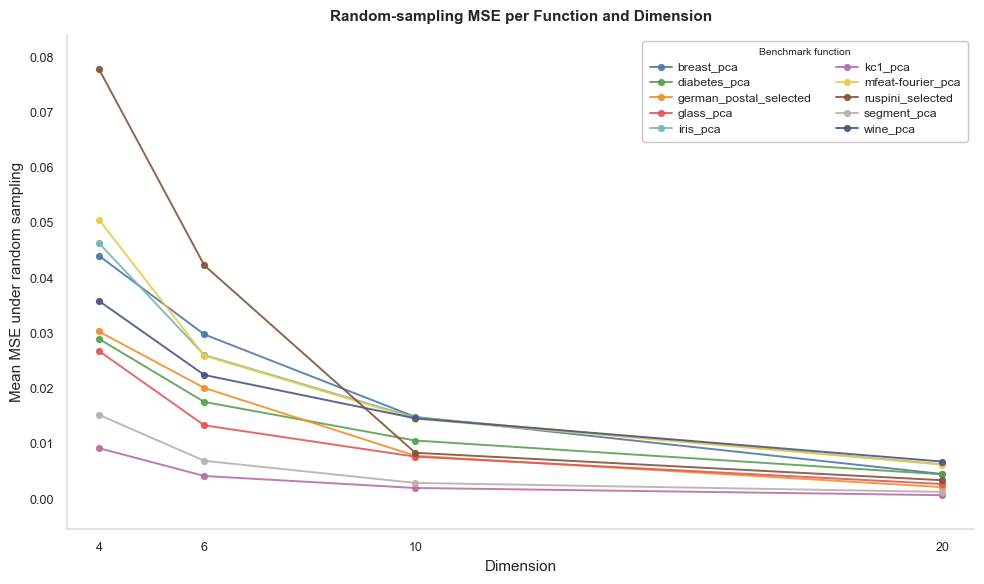

In [13]:
fig, ax = plt.subplots(figsize=(10, 6))

# sort for consistent plotting
df_sorted = problems_df.sort_values(["fid", "k"]).copy()

# yep
df_sorted["mean_mse"] = df_sorted["kpp_mse"]
    

fids = sorted(df_sorted["fid"].unique())


colors = [
    "#4E79A7",  
    "#59A14F",  
    "#F28E2B",  
    "#E15759",  
    "#76B7B2",  
    "#BB6DA5",  
    "#EDC948",  
    "#835439",  
    "#BAB0AC",  
    "#495681",  
]

for i, fid in enumerate(fids):
    grp = df_sorted[df_sorted["fid"] == fid].sort_values("k")
    if grp.empty:
        continue
    label = grp["name"].iloc[0] if "name" in grp.columns else f"fid={fid}"
    color = colors[i % len(colors)]

    ax.plot(
        grp["k"],
        grp["mean_mse"],
        marker="o",
        markersize=4.2,
        linewidth=1.4,
        alpha=0.9,
        color=color,
        label=label,
    )


ax.set_xlabel("Dimension", fontsize=11)
ax.set_ylabel("Mean MSE under random sampling", fontsize=11)

ax.set_title(
    "Random-sampling MSE per Function and Dimension",
    fontsize=11,
    fontweight="semibold",
    pad=10,
)

unique_k = sorted(df_sorted["k"].unique())
ax.set_xticks(unique_k)
ax.set_xticklabels([str(int(k * 2)) for k in unique_k])
ax.set_xlim(min(unique_k) - 0.3, max(unique_k) + 0.3)

y_min = df_sorted["mean_mse"].min()
y_max = df_sorted["mean_mse"].max()
y_pad = 0.08 * (y_max - y_min) if np.isfinite(y_max - y_min) and y_max != y_min else 0.1 * y_max if np.isfinite(y_max) else 1.0

ax.set_ylim(y_min - y_pad, y_max + y_pad)

ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_alpha(0.6)
ax.spines["bottom"].set_alpha(0.6)

ax.tick_params(axis="both", labelsize=9)

# legend
ax.legend(
    title="Benchmark function",
    fontsize=8.8,
    title_fontsize=7.5,
    ncol=2,
    frameon=True,
    framealpha=0.88,
    edgecolor="0.75",
    facecolor="white",
    loc="upper right",
    borderpad=0.6,
    labelspacing=0.4,
    handlelength=1.8,
    handletextpad=0.5
)

plt.tight_layout()
plt.show()



In [14]:
import jsonlines, json, glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy import stats
from pathlib import Path

# experimental setup (missing elitism off & domain know variants of E3 and E4)
EXPERIMENTS = {
    "E1: No domain knowledge": {
        "color": "#7F77DD",        
        "linestyle": "-",
        "runs": sorted(glob.glob(str(results_path / "without_domain_knowledge/*/log.jsonl"))),
    },
    "E2: Domain knowledge": {
        "color": "#1D9E75",        
        "linestyle": "-",
        "runs": sorted(glob.glob(str(results_path / "domain_knowledge/*/log.jsonl"))),
    },
    "E3: No Domain + mutation prompts": {
        "color": "#D80404",        
        "linestyle": "-",
        "runs": sorted(glob.glob(str(results_path / "mutation_5_runs_elitism_on/*/log.jsonl"))),
    },
    "E4: No Domain + warm start": {
        "color": "#BA7517",        
        "linestyle": "-",
        "runs": sorted(glob.glob(str(results_path / "warm_start_5_runs/*/log.jsonl"))),
    },
}
BUDGET = 200

def load_run(path):
    """Return list of fitness values in evaluation order from the log file"""
    records = []
    with jsonlines.open(path) as reader:
        for obj in reader:
            if isinstance(obj, list):        # population snapshot
                for ind in obj:
                    records.append(ind.get("fitness", np.nan))
            elif isinstance(obj, dict):    # individual entry
                records.append(obj.get("fitness", np.nan))
    return np.array(records[:BUDGET], dtype=float)

def best_so_far(arr):
    # running max
    out = np.full_like(arr, np.nan)
    best = -np.inf
    for i, v in enumerate(arr):
        if np.isfinite(v) and v > best:
            best = v
        out[i] = best if np.isfinite(best) else np.nan
    return out

# defined so plotting cells use the current mapping
data = {}
for label, cfg in EXPERIMENTS.items():
    runs = [best_so_far(load_run(p)) for p in cfg.get("runs", [])]
    # pad shorter runs with their final value
    padded = [np.pad(r, (0, BUDGET - len(r)), "edge") if len(r) < BUDGET else r for r in runs]
    data[label] = np.array(padded)

print("Rebuilt data keys and shapes:", {k: v.shape for k, v in data.items()})

Rebuilt data keys and shapes: {'E1: No domain knowledge': (5, 200), 'E2: Domain knowledge': (5, 200), 'E3: No Domain + mutation prompts': (5, 200), 'E4: No Domain + warm start': (5, 200)}


In [15]:
# load everything
data = {}
for label, cfg in EXPERIMENTS.items():
    runs = [best_so_far(load_run(p)) for p in cfg["runs"]]
    # pad shorter runs with their final value
    padded = [np.pad(r, (0, BUDGET - len(r)), "edge")
              if len(r) < BUDGET else r for r in runs]
    data[label] = np.array(padded)  # shape (n_runs, BUDGET)

print({k: v.shape for k, v in data.items()})

{'E1: No domain knowledge': (5, 200), 'E2: Domain knowledge': (5, 200), 'E3: No Domain + mutation prompts': (5, 200), 'E4: No Domain + warm start': (5, 200)}


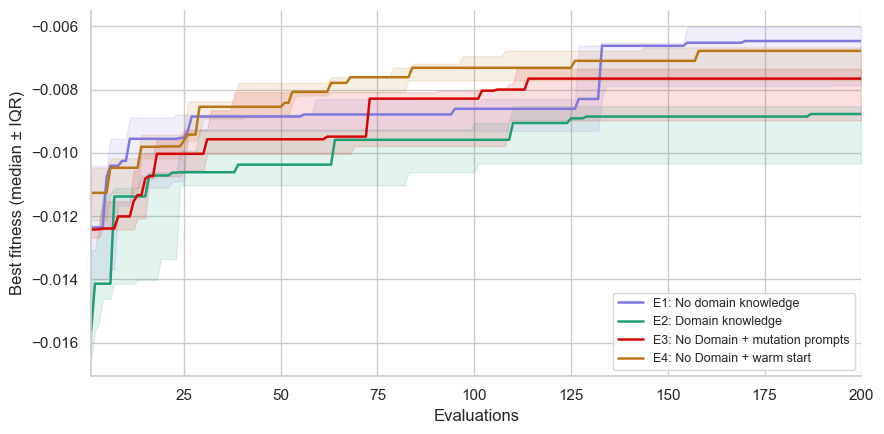

In [16]:
SENTINEL = -1e9

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(1, BUDGET + 1)

for label, cfg in [(l, c) for l, c in EXPERIMENTS.items() if l in ("E1: No domain knowledge", "E2: Domain knowledge", "E3: No Domain + mutation prompts", "E4: No Domain + warm start")]:
    mat = data[label].copy().astype(float)
    if len(mat) == 0: continue

    # mask out inf and sentinel values
    mat[~np.isfinite(mat)] = np.nan
    mat[np.isclose(mat, SENTINEL, atol=1e6)] = np.nan

    # forward fill NaNs with the first finite value for each run
    for i in range(mat.shape[0]):
        finite_mask = np.isfinite(mat[i])
        if np.any(finite_mask):
            first_finite_idx = np.where(finite_mask)[0][0]
            mat[i, :first_finite_idx] = mat[i, first_finite_idx]

    med = np.nanmedian(mat, axis=0)
    q25 = np.nanpercentile(mat, 25, axis=0)
    q75 = np.nanpercentile(mat, 75, axis=0)

    ax.plot(x, med, label=label, color=cfg["color"],
            linestyle=cfg["linestyle"], linewidth=1.8)
    ax.fill_between(x, q25, q75, color=cfg["color"], alpha=0.12)

ax.set_xlabel("Evaluations"); ax.set_ylabel("Best fitness (median ± IQR)")
ax.set_xlim(1, BUDGET); ax.legend(fontsize=9)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout(); plt.show()

In [17]:
rows = []
for label, cfg in EXPERIMENTS.items():
    mat = data[label]
    finals = mat[:, -1]  # best fitness at end of budget per run
    rows.append({
        "Experiment": label,
        "Runs": len(mat),
        "Median final": round(np.nanmedian(finals), 4),
        "IQR": round(np.nanpercentile(finals, 75)
                       - np.nanpercentile(finals, 25), 4),
        "Best": round(np.nanmax(finals), 4),
        "Worst": round(np.nanmin(finals), 4),
    })

df = pd.DataFrame(rows).set_index("Experiment")
display(df)

,Runs,Median final,IQR,Best,Worst
Experiment,,,,,
E1: No domain knowledge,5,-0.0065,0.0019,-0.0045,-0.0097
E2: Domain knowledge,5,-0.0088,0.0018,-0.0044,-0.0106
E3: No Domain + mutation prompts,5,-0.0077,0.0016,-0.0045,-0.0101
E4: No Domain + warm start,5,-0.0068,0.0010,-0.0026,-0.0077


## Generalisabilility 

In [18]:
import jsonlines, json, glob
import numpy as np
import pandas as pd
import iohclustering

# no of cluster centers
K_ALL = [2, 3, 5, 10]

# gen split
test_sets = {
    "same_fid_new_iid":  [(fid, 2, k) for fid in range(1, 9)  for k in K_ALL],
    "new_fid_same_iid":  [(fid, 1, k) for fid in range(9, 11) for k in K_ALL],
    "new_fid_new_iid":   [(fid, 2, k) for fid in range(9, 11) for k in K_ALL],
}

EXPERIMENT_LOGS = {
    "E1": sorted(glob.glob(str(results_path / "without_domain_knowledge/*/log.jsonl"))),
    "E2": sorted(glob.glob(str(results_path / "domain_knowledge/*/log.jsonl"))),
    "E3": sorted(glob.glob(str(results_path / "mutation_5_runs_elitism_on/*/log.jsonl"))),
    "E4": sorted(glob.glob(str(results_path / "warm_start_5_runs/*/log.jsonl"))),
    "E5": sorted(glob.glob(str(results_path / "5_runs_mutation_prompts_WITH_DOMAIN_KNOWLEDGE/*/log.jsonl"))),
    "E6": sorted(glob.glob(str(results_path / "5_runs_warm_start_WITH_DOMAIN_KNOWLEDGE/*/log.jsonl")))   
}


TOP_N = 1

# retrive best algorithm
def extract_top_n(log_paths, n=1):
    individuals = []
    for path in log_paths:
        with jsonlines.open(path) as reader:
            for obj in reader:
                items = obj if isinstance(obj, list) else [obj]
                for ind in items:
                    fitness = float(ind.get("fitness", np.nan))
                    code    = ind.get("code", "")
                    name    = ind.get("name", "")
                    
                    # debug: confirm first alg has all data needed 
                    if len(individuals) < 1:
                        print(f"  keys: {list(ind.keys())}")
                        print(f"  fitness={fitness}, has_code={bool(code)}, name={name}")
                    
                    if code and np.isfinite(fitness):
                        individuals.append({
                            "name":          name,
                            "code":          code,
                            "fitness_train": fitness,
                            "description":   ind.get("description", ""),
                        })

    print(f"  total valid individuals collected: {len(individuals)}")
    
    if not individuals:
        return pd.DataFrame(columns=["name", "code", "fitness_train", "description"])
    
    df = (pd.DataFrame(individuals)
            .sort_values("fitness_train", ascending=False)
            .drop_duplicates(subset="name")
            .head(n)
            .reset_index(drop=True))
    return df

# use the make problem funct from ioh clustering
def _make_problem(fid, iid, k):
    p, _ = iohclustering.get_problem(fid=fid, instance=iid, k=k)
    return p

# load  baseline 
kmeans_df = pd.read_csv(BASE_DIR / "KMeansCompare.csv")  
kmeans_df = kmeans_df.rename(columns={"dataset": "fid"})
# print(kmeans_df.head())  # check column names

# look up table for kmeans baseline MSE
kmeans_min = {
    (int(row["fid"]), int(row["k"])): float(row["mse"]) 
    for _, row in kmeans_df.iterrows()
}

# evaluate alg performance 
def evaluate_algorithm(code, fid, iid, k, budget_per_dim=25):
    namespace = {}
    try:
        exec(code, namespace)
    except Exception as e:
        return np.nan, f"exec failed: {e}"

    algo_class = next(
        (v for v in namespace.values()
         if isinstance(v, type) and hasattr(v, "__call__") and v.__name__ != "type"),
        None,
    )
    if algo_class is None:
        return np.nan, "no callable class found"

    try:
        problem = _make_problem(fid, iid, k)
        dim     = problem.meta_data.n_variables
        budget  = budget_per_dim * dim

        class TrackedProblem:
            def __init__(self, p, k):
                self._p         = p
                self.best_mse   = np.inf
                self.best_curve = []
                self.bounds     = type("Bounds", (), {
                    "lb": np.zeros(k * 2),
                    "ub": np.ones(k * 2),
                })()

            def __call__(self, x):
                result = self._p(x)
                mse    = result[0] if isinstance(result, tuple) else float(result)
                if mse < self.best_mse:
                    self.best_mse = mse
                self.best_curve.append(self.best_mse)
                return result

            def __getattr__(self, name):
                return getattr(self._p, name)

        tracked = TrackedProblem(problem, k)
        algo    = algo_class(budget=budget, dim=k * 2)
        algo(tracked)

        baseline_mse = kmeans_min.get((int(fid), int(k)))
        if baseline_mse is None:
            return np.nan, f"no baseline for fid={fid} k={k}"

        best_curve = np.array(tracked.best_curve[:budget], dtype=float)
        if len(best_curve) < budget:
            best_curve = np.pad(best_curve, (0, budget - len(best_curve)), mode="edge")

        improvement_curve = baseline_mse - best_curve
        auc_imp           = float(np.mean(improvement_curve))
        return auc_imp, None

    except Exception as e:
        return np.nan, str(e)

# get best algs and eval them 
rows = []
for exp_name, log_paths in EXPERIMENT_LOGS.items():
    print(f"\n── {exp_name} ──")
    top = extract_top_n(log_paths, n=TOP_N)

    if top.empty:
        print(f"  No valid algorithms found for {exp_name}")
        continue

    best = top.iloc[0]
    print(f"  Best: {best['name']} (train fitness: {best['fitness_train']:.4f})")

    for test_set_name, instances in test_sets.items():
        for fid, iid, k in instances:
            fitness, err = evaluate_algorithm(best["code"], fid, iid, k)
            if err:
                print(f"    fid={fid} iid={iid} k={k}: {err}")
            rows.append({
                "experiment":    exp_name,
                "algo_name":     best["name"],
                "fitness_train": best["fitness_train"],
                "test_set":      test_set_name,
                "fid":           fid,
                "iid":           iid,
                "k":             k,
                "fitness_test":  fitness,
            })

df = pd.DataFrame(rows)
df.to_csv(BASE_DIR / "generalizability_results_overwrite.csv", index=False)
print("\nSaved to generalizability_results.csv")




── E1 ──
  keys: ['id', 'fitness', 'name', 'description', 'code', 'configspace', 'generation', 'feedback', 'error', 'parent_ids', 'operator', 'metadata', 'task_prompt']
  fitness=-0.017251303918327545, has_code=True, name=AdaptiveLocalSearch
  total valid individuals collected: 925
  Best: ChaoticLocalSearch (train fitness: -0.0045)

── E2 ──
  keys: ['id', 'fitness', 'name', 'description', 'code', 'configspace', 'generation', 'feedback', 'error', 'parent_ids', 'operator', 'metadata', 'task_prompt']
  fitness=-0.010716877919311838, has_code=True, name=AdaptiveClusteringOptimizer
  total valid individuals collected: 818
  Best: SpectralClusteringOptimizer (train fitness: -0.0044)

── E3 ──
  keys: ['id', 'fitness', 'name', 'description', 'code', 'configspace', 'generation', 'feedback', 'error', 'parent_ids', 'operator', 'metadata', 'task_prompt']
  fitness=-0.012424129379774315, has_code=True, name=AdaptivePSOClustering
  total valid individuals collected: 922
  Best: AdaptiveESCluster

In [19]:
import re
import numpy as np
import pandas as pd

df = pd.read_csv(BASE_DIR / "generalizability_results_overwrite.csv")

def extract_first_float(value):
    """
    Extract the first float from values like:
    '(0.04739870521144242, array([...]))'
    """
    if pd.isna(value):
        return np.nan

    if isinstance(value, (int, float, np.number)):
        return float(value)

    text = str(value)

    match = re.search(r"[-+]?\d*\.\d+(?:[eE][-+]?\d+)?|[-+]?\d+", text)

    if match:
        return float(match.group(0))

    return np.nan


df["fitness_test_raw"] = df["fitness_test"]
df["fitness_test"] = df["fitness_test"].apply(extract_first_float)

print("Total rows:", len(df))
print("Valid fitness_test rows:", df["fitness_test"].notna().sum())
print("Failed/NaN rows:", df["fitness_test"].isna().sum())

df.head()

Total rows: 288
Valid fitness_test rows: 288
Failed/NaN rows: 0


,experiment,algo_name,fitness_train,test_set,fid,iid,k,fitness_test,fitness_test_raw
0,E1,ChaoticLocalSearch,-0.004464,same_fid_new_iid,1,2,2,-0.005747,-0.005747
1,E1,ChaoticLocalSearch,-0.004464,same_fid_new_iid,1,2,3,-0.011545,-0.011545
2,E1,ChaoticLocalSearch,-0.004464,same_fid_new_iid,1,2,5,-0.008017,-0.008017
3,E1,ChaoticLocalSearch,-0.004464,same_fid_new_iid,1,2,10,-0.009694,-0.009694
4,E1,ChaoticLocalSearch,-0.004464,same_fid_new_iid,2,2,2,-0.014926,-0.014926


In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

# load generalisability results
df = pd.read_csv(BASE_DIR / "generalizability_results_overwrite.csv")

# check
df["fitness_test"] = pd.to_numeric(df["fitness_test"], errors="coerce")

# load KMeans++ baseline
kmeans_df = pd.read_csv(BASE_DIR / "KMeansCompare.csv")
kmeans_df = kmeans_df.rename(columns={"dataset": "fid", "mse": "kmeans_mse"})

# merge table
df = df.merge(
    kmeans_df[["fid", "k", "kmeans_mse"]],
    on=["fid", "k"],
    how="left"
)

# recalculate MSE-equivalent value
df["mean_best_mse"] = df["kmeans_mse"] - df["fitness_test"]

print("Total rows:", len(df))
print("Valid mean_best_mse rows:", df["mean_best_mse"].notna().sum())
print("Rows missing baseline:", df["kmeans_mse"].isna().sum())

df[[
    "experiment",
    "algo_name",
    "test_set",
    "fid",
    "iid",
    "k",
    "kmeans_mse",
    "fitness_test",
    "mean_best_mse"
]].head()

Total rows: 288
Valid mean_best_mse rows: 288
Rows missing baseline: 0


,experiment,algo_name,test_set,fid,iid,k,kmeans_mse,fitness_test,mean_best_mse
0,E1,ChaoticLocalSearch,same_fid_new_iid,1,2,2,0.044068,-0.016457,0.060526
1,E1,ChaoticLocalSearch,same_fid_new_iid,1,2,3,0.029825,-0.012577,0.042402
2,E1,ChaoticLocalSearch,same_fid_new_iid,1,2,5,0.014901,-0.008124,0.023025
3,E1,ChaoticLocalSearch,same_fid_new_iid,1,2,10,0.004568,-0.006449,0.011016
4,E1,ChaoticLocalSearch,same_fid_new_iid,2,2,2,0.029030,-0.024482,0.053512


In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# copy and use gen df
df_gen = df.copy()
# clean
df_gen["fitness_test"] = pd.to_numeric(df_gen["fitness_test"], errors="coerce")

df_gen_clean = df_gen.dropna(subset=["fitness_test"]).copy()

print("Total rows:", len(df_gen))
print("Valid fitness_test rows:", len(df_gen_clean))
print("Failed/NaN rows:", len(df_gen) - len(df_gen_clean))

# group by gen experiment type and calculate summary vals 

summary_test_set = (
    df_gen
    .groupby(["experiment", "test_set"], as_index=False)
    .agg(
        mean_fitness_test=("fitness_test", "mean"),
        median_fitness_test=("fitness_test", "median"),
        std_fitness_test=("fitness_test", "std"),
        min_fitness_test=("fitness_test", "min"),
        max_fitness_test=("fitness_test", "max"),
        n_evaluations=("fitness_test", "count"),
        n_algorithms=("algo_name", "nunique"),
        n_fids=("fid", "nunique"),
        n_k_values=("k", "nunique"),
    )
)

summary_test_set

Total rows: 288
Valid fitness_test rows: 288
Failed/NaN rows: 0


,experiment,test_set,mean_fitness_test,median_fitness_test,std_fitness_test,min_fitness_test,max_fitness_test,n_evaluations,n_algorithms,n_fids,n_k_values
0,E1,new_fid_new_iid,-0.012089,-0.011706,0.005620,-0.022615,-0.004906,8,1,2,4
1,E1,new_fid_same_iid,-0.015586,-0.012617,0.011628,-0.040478,-0.005699,8,1,2,4
2,E1,same_fid_new_iid,-0.012825,-0.010274,0.008491,-0.049025,-0.003452,32,1,8,4
3,E2,new_fid_new_iid,-0.008503,-0.008424,0.003390,-0.014665,-0.004669,8,1,2,4
4,E2,new_fid_same_iid,-0.009968,-0.009374,0.004498,-0.017387,-0.005128,8,1,2,4
5,E2,same_fid_new_iid,-0.010240,-0.007375,0.006631,-0.029047,-0.002920,32,1,8,4
6,E3,new_fid_new_iid,-0.012528,-0.010066,0.009655,-0.034133,-0.004209,8,1,2,4
7,E3,new_fid_same_iid,-0.007953,-0.006075,0.005815,-0.020767,-0.002650,8,1,2,4
8,E3,same_fid_new_iid,-0.009047,-0.007806,0.004533,-0.019223,-0.002000,32,1,8,4
9,E4,new_fid_new_iid,-0.010076,-0.008146,0.006161,-0.021667,-0.003703,8,1,2,4


In [35]:
summary_test_set_mse = (
    df
    .dropna(subset=["mean_best_mse"])
    .groupby(["experiment", "test_set"], as_index=False)
    .agg(
        mean_mse=("mean_best_mse", "mean"),
        median_mse=("mean_best_mse", "median"),
        std_mse=("mean_best_mse", "std"),
        min_mse=("mean_best_mse", "min"),
        max_mse=("mean_best_mse", "max"),
        n_evaluations=("mean_best_mse", "count"),
        n_algorithms=("algo_name", "nunique"),
        n_fids=("fid", "nunique"),
        n_k_values=("k", "nunique"),
    )
)

summary_test_set_mse

,experiment,test_set,mean_mse,median_mse,std_mse,min_mse,max_mse,n_evaluations,n_algorithms,n_fids,n_k_values
0,E1,new_fid_new_iid,0.025387,0.022655,0.015023,0.006237,0.051849,8,1,2,4
1,E1,new_fid_same_iid,0.028884,0.024017,0.019039,0.007029,0.056052,8,1,2,4
2,E1,same_fid_new_iid,0.031751,0.025045,0.023624,0.004198,0.098698,32,1,8,4
3,E2,new_fid_new_iid,0.021802,0.018238,0.013493,0.006000,0.045464,8,1,2,4
4,E2,new_fid_same_iid,0.023266,0.022097,0.013028,0.006459,0.045271,8,1,2,4
5,E2,same_fid_new_iid,0.029167,0.022611,0.023236,0.003666,0.099985,32,1,8,4
6,E3,new_fid_new_iid,0.025826,0.021517,0.016957,0.005539,0.051559,8,1,2,4
7,E3,new_fid_same_iid,0.021251,0.019089,0.013416,0.003980,0.040184,8,1,2,4
8,E3,same_fid_new_iid,0.027974,0.021732,0.021358,0.002746,0.095620,32,1,8,4
9,E4,new_fid_new_iid,0.023375,0.022904,0.013571,0.005034,0.042699,8,1,2,4


In [36]:
summary_fid_k_mse = (
    df
    .dropna(subset=["mean_best_mse"])
    .groupby(["experiment", "test_set", "fid", "k"], as_index=False)
    .agg(
        mean_mse=("mean_best_mse", "mean"),
        median_mse=("mean_best_mse", "median"),
        std_mse=("mean_best_mse", "std"),
        min_mse=("mean_best_mse", "min"),
        max_mse=("mean_best_mse", "max"),
        n_evaluations=("mean_best_mse", "count"),
        n_algorithms=("algo_name", "nunique"),
    )
)

# Uncomment if needed
# summary_fid_k_mse.to_csv(BASE_DIR / "generalizability_mse_by_fid_k.csv", index=False)
summary_fid_k_mse

,experiment,test_set,fid,k,mean_mse,median_mse,std_mse,min_mse,max_mse,n_evaluations,n_algorithms
0,E1,new_fid_new_iid,9,2,0.037903,0.037903,NaN,0.037903,0.037903,1,1
1,E1,new_fid_new_iid,9,3,0.020727,0.020727,NaN,0.020727,0.020727,1,1
2,E1,new_fid_new_iid,9,5,0.015015,0.015015,NaN,0.015015,0.015015,1,1
3,E1,new_fid_new_iid,9,10,0.006237,0.006237,NaN,0.006237,0.006237,1,1
4,E1,new_fid_new_iid,10,2,0.051849,0.051849,NaN,0.051849,0.051849,1,1
...,...,...,...,...,...,...,...,...,...,...,...
283,E6,same_fid_new_iid,7,10,0.011368,0.011368,NaN,0.011368,0.011368,1,1
284,E6,same_fid_new_iid,8,2,0.110611,0.110611,NaN,0.110611,0.110611,1,1
285,E6,same_fid_new_iid,8,3,0.076698,0.076698,NaN,0.076698,0.076698,1,1
286,E6,same_fid_new_iid,8,5,0.020511,0.020511,NaN,0.020511,0.020511,1,1


In [37]:
print("Train fitness range:", df["fitness_train"].min(), "to", df["fitness_train"].max())
print("Test fitness range: ", df["fitness_test"].min(),  "to", df["fitness_test"].max())
print("\nSample train values:", df["fitness_train"].head(5).tolist())
print("Sample test values: ", df["fitness_test"].head(5).tolist())

Train fitness range: -0.0056790929108949 to -0.0025830443137061
Test fitness range:  -0.0556106737348902 to -0.0020002319009672

Sample train values: [-0.0044643211651933, -0.0044643211651933, -0.0044643211651933, -0.0044643211651933, -0.0044643211651933]
Sample test values:  [-0.0164572847527905, -0.0125769041406015, -0.0081244399716866, -0.0064487822655127, -0.024481848473044]


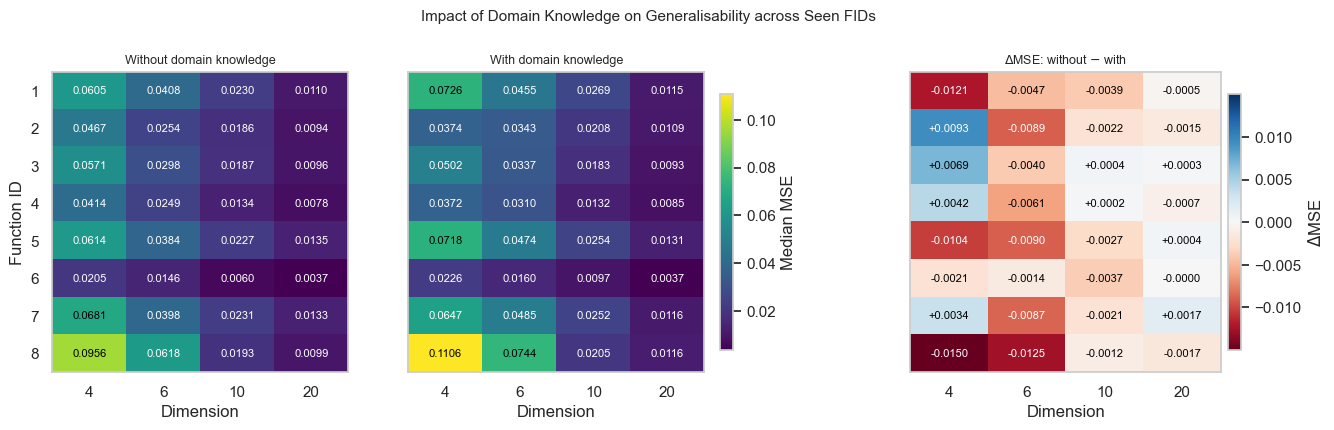

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


DOMAIN_KNOWLEDGE_GROUPS = {
    "without_domain": ["E1", "E3", "E4"],
    "with_domain":    ["E2", "E5", "E6"],
}


TEST_SET_LABELS = {
    "same_fid_new_iid": "Seen FIDs",
    "new_fid_same_iid": "Unseen FIDs + check",
    "new_fid_new_iid": "Unseen FIDs",
}


def get_group_pivot(
    summary_fid_k_mse,
    experiments,
    test_set,
    value_col="mean_mse",
    agg="median",
):
    subset = summary_fid_k_mse[
        (summary_fid_k_mse["experiment"].isin(experiments)) &
        (summary_fid_k_mse["test_set"] == test_set)
    ].copy()

    if subset.empty:
        return None

    if agg == "median":
        grouped = subset.groupby(["fid", "k"])[value_col].median().reset_index()
    elif agg == "mean":
        grouped = subset.groupby(["fid", "k"])[value_col].mean().reset_index()
    else:
        raise ValueError("agg must be 'median' or 'mean'.")

    pivot = grouped.pivot(index="fid", columns="k", values=value_col)
    return pivot

def get_text_color(value, vmin, vmax, cmap_name):
    if vmax <= vmin:
        normed = 0.5
    else:
        normed = (value - vmin) / (vmax - vmin)
    # make sure text is readable 
    if cmap_name == "viridis":
        return "white" if normed < 0.6 else "black"
    elif cmap_name == "RdBu":
        return "white" if (normed < 0.25 or normed > 0.75) else "black"
    else:
        return "white" if normed < 0.5 else "black"
    
def plot_domain_knowledge_three_panel_heatmap(
    summary_fid_k_mse,
    groups,
    test_set,
    value_col="mean_mse",
    agg="median",
    mse_cmap="viridis",
    diff_cmap="RdBu",
    stat_annotation=None,
    save_path=None,
):
    # Panel 1 MSE without domain knowledge

    # Positive ΔMSE means domain knowledge lowers MSE.
    # Negative ΔMSE means domain knowledge worsens MSE.


    without_pivot = get_group_pivot(
        summary_fid_k_mse,
        groups["without_domain"],
        test_set,
        value_col=value_col,
        agg=agg,
    )

    with_pivot = get_group_pivot(
        summary_fid_k_mse,
        groups["with_domain"],
        test_set,
        value_col=value_col,
        agg=agg,
    )

    if without_pivot is None or with_pivot is None:
        print(f"No data available for test_set={test_set}")
        return None

    # align indices and columns
    all_fids = sorted(set(without_pivot.index).union(set(with_pivot.index)))
    all_ks = sorted(set(without_pivot.columns).union(set(with_pivot.columns)))

    without_pivot = without_pivot.reindex(index=all_fids, columns=all_ks)
    with_pivot = with_pivot.reindex(index=all_fids, columns=all_ks)

    diff_pivot = without_pivot - with_pivot

    without_values = without_pivot.values.astype(float)
    with_values = with_pivot.values.astype(float)
    diff_values = diff_pivot.values.astype(float)

    # shared colour scale for the two raw MSE heatmaps
    mse_values = np.concatenate([
        without_values.ravel(),
        with_values.ravel()
    ])
    mse_values = mse_values[np.isfinite(mse_values)]

    mse_vmin = np.nanmin(mse_values)
    mse_vmax = np.nanmax(mse_values)

    # symmetric colour scale for ΔMSE 
    diff_absmax = np.nanmax(np.abs(diff_values))
    diff_vmin = -diff_absmax
    diff_vmax = diff_absmax

    n_fids = len(all_fids)
    n_ks = len(all_ks)

    # size each panel based on actual grid shape (cols x rows) rather than a fixed
    # allow for clear scaling of train set and test sets
    cell_size = 0.8
    panel_width = max(3.0, cell_size * n_ks + 1.6)   # +1.6 for labels/margins
    panel_height = max(2.25, cell_size * n_fids - 2.5)
    fig_width = panel_width * 3 + 1.5  # extra room for colourbars
    fig_height = panel_height

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(fig_width, fig_height),
        sharey=True,
        gridspec_kw={"width_ratios": [1, 1, 1.05]}
    )

    panels = [
        {
            "ax": axes[0],
            "values": without_values,
            "title": "Without domain knowledge",
            "cmap": mse_cmap,
            "vmin": mse_vmin,
            "vmax": mse_vmax,
            "label": f"{agg.capitalize()} MSE",
            "fmt": "{:.4f}",
        },
        {
            "ax": axes[1],
            "values": with_values,
            "title": "With domain knowledge",
            "cmap": mse_cmap,
            "vmin": mse_vmin,
            "vmax": mse_vmax,
            "label": f"{agg.capitalize()} MSE",
            "fmt": "{:.4f}",
        },
        {
            "ax": axes[2],
            "values": diff_values,
            "title": r"$\Delta$MSE: without $-$ with",
            "cmap": diff_cmap,
            "vmin": diff_vmin,
            "vmax": diff_vmax,
            "label": r"$\Delta$MSE",
            "fmt": "{:+.4f}",
        },
    ]

    mse_im = None
    diff_im = None

    for panel in panels:
        ax = panel["ax"]
        values = panel["values"]
        cmap_name = panel["cmap"]

        im = ax.imshow(
            values,
            aspect="auto",
            cmap=panel["cmap"],
            vmin=panel["vmin"],
            vmax=panel["vmax"]
        )

        if panel["title"].startswith("Without"):
            mse_im = im
        if "Δ" in panel["title"] or "Delta" in panel["title"]:
            diff_im = im

        ax.set_title(panel["title"], fontsize=9)
        ax.set_xlabel("Dimension")
        dim = [4, 6, 10, 20]
        ax.set_xticks(np.arange(len(dim)))
        ax.set_xticklabels(dim)

        ax.set_yticks(np.arange(len(all_fids)))
        ax.set_yticklabels(all_fids)

        # only central value, no range
        for i in range(values.shape[0]):
            for j in range(values.shape[1]):
                value = values[i, j]

                if np.isfinite(value):
                    if panel["vmax"] > panel["vmin"]:
                        normed = (value - panel["vmin"]) / (panel["vmax"] - panel["vmin"])
                    else:
                        normed = 0.5

                    # make sure text is readable
                    text_color = get_text_color(value, panel["vmin"], panel["vmax"], cmap_name)

                    ax.text(
                        j,
                        i,
                        panel["fmt"].format(value),
                        ha="center",
                        va="center",
                        fontsize=8,
                        color=text_color
                    )
                    ax.grid(False)

    axes[0].set_ylabel("Function ID")

    test_set_title = TEST_SET_LABELS.get(test_set, test_set)

    fig.suptitle(
        f"Impact of Domain Knowledge on Generalisability across {test_set_title}",
        y=1.04,
        fontsize=11
    )

    # colourbars
    cbar_mse = fig.colorbar(mse_im, ax=axes[:2], shrink=0.85, pad=0.02)
    cbar_mse.set_label(f"{agg.capitalize()} MSE")

    cbar_diff = fig.colorbar(diff_im, ax=axes[2], shrink=0.85, pad=0.02)
    cbar_diff.set_label(
        r"$\Delta$MSE"
    )

    if stat_annotation:
        fig.text(
            0.5, -0.02, stat_annotation,
            ha="center", fontsize=9, style="italic"
        )

    if save_path is not None:
        plt.savefig(f"{save_path}.pdf", bbox_inches="tight")
        plt.savefig(f"{save_path}.png", dpi=300, bbox_inches="tight")

    plt.show()

    return {
        "without": without_pivot,
        "with": with_pivot,
        "diff": diff_pivot,
    }

TEST_SET_LABELS = {
    "same_fid_new_iid": "Seen FIDs",
}

for test_set_key in TEST_SET_LABELS:
    plot_domain_knowledge_three_panel_heatmap(
        summary_fid_k_mse,
        DOMAIN_KNOWLEDGE_GROUPS,
        test_set=test_set_key,
        agg="median",
        save_path=f"domain_knowledge_{test_set_key}_three_panel"
    )

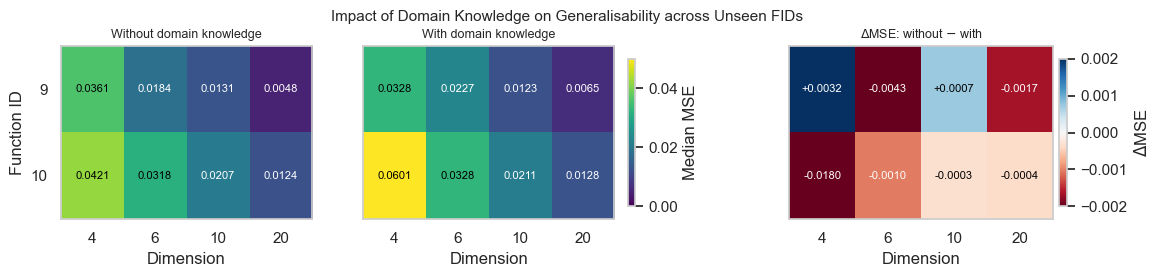

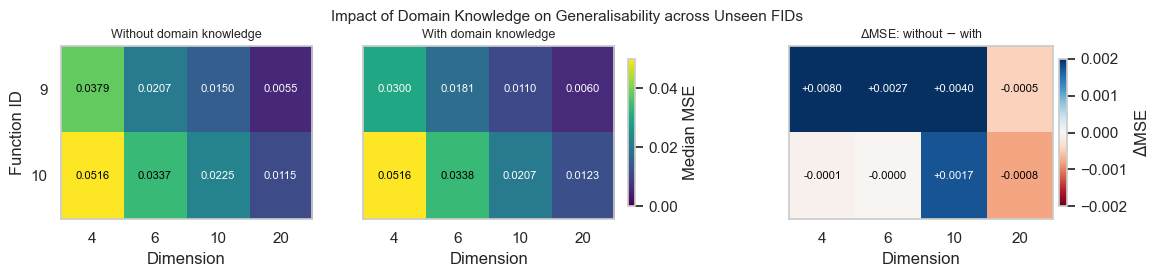

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def get_group_pivot(
    summary_fid_k_mse,
    experiments,
    test_set,
    value_col="mean_mse",
    agg="median",
):
    subset = summary_fid_k_mse[
        (summary_fid_k_mse["experiment"].isin(experiments)) &
        (summary_fid_k_mse["test_set"] == test_set)
    ].copy()

    if subset.empty:
        return None

    if agg == "median":
        grouped = subset.groupby(["fid", "k"])[value_col].median().reset_index()
    elif agg == "mean":
        grouped = subset.groupby(["fid", "k"])[value_col].mean().reset_index()
    else:
        raise ValueError("agg must be 'median' or 'mean'.")

    pivot = grouped.pivot(index="fid", columns="k", values=value_col)
    return pivot

def get_text_color(value, vmin, vmax, cmap_name):
    if vmax <= vmin:
        normed = 0.5
    else:
        normed = (value - vmin) / (vmax - vmin)
    # make sure text is readable 
    if cmap_name == "viridis":
        return "white" if normed < 0.6 else "black"
    elif cmap_name == "RdBu":
        return "white" if (normed < 0.25 or normed > 0.75) else "black"
    else:
        return "white" if normed < 0.5 else "black"
    
def plot_domain_knowledge_three_panel_heatmap(
    summary_fid_k_mse,
    groups,
    test_set,
    value_col="mean_mse",
    agg="median",
    mse_cmap="viridis",
    diff_cmap="RdBu",
    stat_annotation=None,
    save_path=None,
):
    # Panel 2 MSE with domain knowledge & Panel 3 MSE = MSE_without - MSE_with

    # Positive ΔMSE means domain knowledge lowers MSE.
    # Negative ΔMSE means domain knowledge worsens MSE.

    without_pivot = get_group_pivot(
        summary_fid_k_mse,
        groups["without_domain"],
        test_set,
        value_col=value_col,
        agg=agg,
    )

    with_pivot = get_group_pivot(
        summary_fid_k_mse,
        groups["with_domain"],
        test_set,
        value_col=value_col,
        agg=agg,
    )

    if without_pivot is None or with_pivot is None:
        print(f"No data available for test_set={test_set}")
        return None

    # align indices and columns
    all_fids = sorted(set(without_pivot.index).union(set(with_pivot.index)))
    all_ks = sorted(set(without_pivot.columns).union(set(with_pivot.columns)))

    without_pivot = without_pivot.reindex(index=all_fids, columns=all_ks)
    with_pivot = with_pivot.reindex(index=all_fids, columns=all_ks)

    diff_pivot = without_pivot - with_pivot

    without_values = without_pivot.values.astype(float)
    with_values = with_pivot.values.astype(float)
    diff_values = diff_pivot.values.astype(float)

    # fixed colour scale to clearly see differences
    mse_vmin = 0.0
    mse_vmax = 0.05
    diff_vmin = -0.002
    diff_vmax = 0.002

    n_fids = len(all_fids)
    n_ks = len(all_ks)

    # scaling 
    cell_size = 0.6
    panel_width = max(3.0, cell_size * n_ks + 1.6)   # +1.6 for labels/margins
    panel_height = max(2.25, cell_size * n_fids - 2.5)
    fig_width = panel_width * 3 + 1.5  # extra room for colourbars
    fig_height = panel_height

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(fig_width, fig_height),
        sharey=True,
        gridspec_kw={"width_ratios": [1, 1, 1.05]}
    )

    panels = [
        {
            "ax": axes[0],
            "values": without_values,
            "title": "Without domain knowledge",
            "cmap": mse_cmap,
            "vmin": mse_vmin,
            "vmax": mse_vmax,
            "label": f"{agg.capitalize()} MSE",
            "fmt": "{:.4f}",
        },
        {
            "ax": axes[1],
            "values": with_values,
            "title": "With domain knowledge",
            "cmap": mse_cmap,
            "vmin": mse_vmin,
            "vmax": mse_vmax,
            "label": f"{agg.capitalize()} MSE",
            "fmt": "{:.4f}",
        },
        {
            "ax": axes[2],
            "values": diff_values,
            "title": r"$\Delta$MSE: without $-$ with",
            "cmap": diff_cmap,
            "vmin": diff_vmin,
            "vmax": diff_vmax,
            "label": r"$\Delta$MSE",
            "fmt": "{:+.4f}",
        },
    ]

    mse_im = None
    diff_im = None

    for panel in panels:
        ax = panel["ax"]
        values = panel["values"]
        cmap_name = panel["cmap"]

        im = ax.imshow(
            values,
            aspect="auto",
            cmap=panel["cmap"],
            vmin=panel["vmin"],
            vmax=panel["vmax"]
        )

        if panel["title"].startswith("Without"):
            mse_im = im
        if "Δ" in panel["title"] or "Delta" in panel["title"]:
            diff_im = im

        ax.set_title(panel["title"], fontsize=9)
        ax.set_xlabel("Dimension")
        dim = [4, 6, 10, 20]
        ax.set_xticks(np.arange(len(dim)))
        ax.set_xticklabels(dim)

        ax.set_yticks(np.arange(len(all_fids)))
        ax.set_yticklabels(all_fids)

        # only central value, no range
        for i in range(values.shape[0]):
            for j in range(values.shape[1]):
                value = values[i, j]

                if np.isfinite(value):
                    if panel["vmax"] > panel["vmin"]:
                        normed = (value - panel["vmin"]) / (panel["vmax"] - panel["vmin"])
                    else:
                        normed = 0.5

                    text_color = get_text_color(value, panel["vmin"], panel["vmax"], cmap_name)

                    ax.text(
                        j,
                        i,
                        panel["fmt"].format(value),
                        ha="center",
                        va="center",
                        fontsize=8,
                        color=text_color
                    )
                    ax.grid(False)

    axes[0].set_ylabel("Function ID")

    test_set_title = TEST_SET_LABELS.get(test_set, test_set)

    fig.suptitle(
        f"Impact of Domain Knowledge on Generalisability across {test_set_title}",
        y=1.04,
        fontsize=11
    )

    # colourbars
    cbar_mse = fig.colorbar(mse_im, ax=axes[:2], shrink=0.85, pad=0.02)
    cbar_mse.set_label(f"{agg.capitalize()} MSE")

    cbar_diff = fig.colorbar(diff_im, ax=axes[2], shrink=0.85, pad=0.02)
    cbar_diff.set_label(r"$\Delta$MSE")

    if stat_annotation:
        fig.text(
            0.5, -0.02, stat_annotation,
            ha="center", fontsize=9, style="italic"
        )

    if save_path is not None:
        plt.savefig(f"{save_path}.pdf", bbox_inches="tight")
        plt.savefig(f"{save_path}.png", dpi=300, bbox_inches="tight")

    plt.show()

    return {
        "without": without_pivot,
        "with": with_pivot,
        "diff": diff_pivot,
    }

TEST_SET_LABELS = {
    "new_fid_same_iid": "Unseen FIDs",
    "new_fid_new_iid": "Unseen FIDs",
}

for test_set_key in TEST_SET_LABELS:
    plot_domain_knowledge_three_panel_heatmap(
        summary_fid_k_mse,
        DOMAIN_KNOWLEDGE_GROUPS,
        test_set=test_set_key,
        agg="median",
        save_path=f"domain_knowledge_{test_set_key}_three_panel"
    )


## Algorithm Categories proportion and how it changes over a single run 

In [27]:
EXPERIMENTS = {
    "E3: Exemplar-injection + Without Elitism": {
        "color": "#7F77DD",
        "linestyle": "-",
        "runs": sorted(glob.glob(str(results_path / "mutation_5_runs_elitism_off_16/*/log.jsonl"))),
    },
    "E4: Warm Start + Without Elitism": {
        "color": "#1D9E75",
        "linestyle": "-",
        "runs": sorted(glob.glob(str(results_path / "warm_start_5_runs_elitism_off_16_child/*/log.jsonl"))),
    },
    "E3: Exemplar-injection + Elitism": {
        "color": "#D80404",
        "linestyle": "--",
        "runs": sorted(glob.glob(str(results_path / "mutation_5_runs_elitism_on/*/log.jsonl"))),
    },
    "E4: Warm Start + Elitism": {
        "color": "#BA7517",
        "linestyle": "--",
        "runs": sorted(glob.glob(str(results_path / "warm_start_5_runs/*/log.jsonl"))),
    },
}

BUDGET = 200

# load all logs
records = []

for exp_label, exp_cfg in EXPERIMENTS.items():
    for run_path in exp_cfg["runs"]:
        try:
            with jsonlines.open(run_path) as reader:
                for call_idx, entry in enumerate(reader, start=1):
                    records.append({
                        "experiment":  exp_label,
                        "run":         run_path,
                        "call":        call_idx,
                        "name":        entry.get("name"),
                        "code":        entry.get("code"),
                        "description": entry.get("description", ""),
                        "fitness":     entry.get("fitness") or entry.get("score"),
                    })
        except Exception as e:
            print(f"Failed to load {run_path}: {e}")

log_df = pd.DataFrame(records)
print(f"Total rows loaded: {len(log_df)}")
print(log_df["experiment"].value_counts())

# classify the generated algorithm into different types 
# log_df["algorithm_category"] = log_df.apply(
#     lambda r: classify_algorithm(r["name"], r.get("description", "")),
#     axis=1
# )

Total rows loaded: 3976
experiment
E4: Warm Start + Without Elitism            1000
E3: Exemplar-injection + Elitism            1000
E4: Warm Start + Elitism                    1000
E3: Exemplar-injection + Without Elitism     976
Name: count, dtype: int64


In [28]:
# classification map 
def classify_algorithm(name: str, description: str = None) -> str:
    if pd.isna(name):
        return "Other"

    n = str(name).strip().upper()
    desc = str(description).strip().upper() if description and not pd.isna(description) else ""

    # check alg name 
    explicit_map = {
        "HYBRIDDELOCALSEARCH": "ES",
        "CLUSTERINGHYBRIDOPTIMIZER": "DE",
        "CHAOSENHANCEDCLUSTERINGOPTIMIZER": "DE",
        "ADAPTIVECHAOTICCLUSTERINGOPTIMIZER": "DE",
        "ENTROPYDRIVENCLUSTERINGOPTIMIZER": "DE",
        "CHAOTICHYBRIDCLUSTERINGOPTIMIZER": "DE",
        "HYBRIDCLUSTERINGOPTIMIZER": "DE",
        "ADAPTIVEESCLUSTERING": "ES",
        "ADAPTIVEPSOCLUSTERING": "PSO",
        "ADAPTIVEMULTISWARMCLUSTERING": "PSO",
        "ADAPTIVECLUSTERINGEA": "ES",
        "ECA": "ES",
    }

    if n in explicit_map:
        return explicit_map[n]

    # SA check name first, then description
    if "SIMULATED" in n or "ANNEALING" in n or "SA" == n:
        return "SA"
    if "SIMULATED ANNEALING" in desc or "ANNEALING" in desc:
        return "SA"

    if "PSO" in n or "SWARM" in n:
        return "PSO"

    if "UMDA" in n or "EDA" in n:
        return "EDA"

    # name contains DE signals AND local search signals
    de_signal = "DE" in n or "DIFFERENTIAL" in n
    local_search_signal = (
        "MEMETIC" in n or "LOCAL" in n or "LOCAL SEARCH" in desc
        or "LOCAL-SEARCH" in desc or "MEMETIC" in desc
    )

    # chose to classify DE + local search as DE
    if de_signal and local_search_signal:
        return "DE"

    if de_signal:
        return "DE"

    # pure memetic: name says memetic, or description mentions local search
    if "MEMETIC" in n or local_search_signal:
        return "MA"

    if "EA" in n or "EVOLUTIONARY" in n or "ES" in n or "ECA" in n or "ADAPTIVECLUSTERING" in n:
        return "ES"

    return "ES"


# pass description column if available
if "description" in log_df.columns:
    log_df["algorithm_category"] = log_df.apply(
        lambda r: classify_algorithm(r["name"], r.get("description")), axis=1
    )
else:
    log_df["algorithm_category"] = log_df["name"].apply(classify_algorithm)

categories = ["ES", "DE", "PSO", "Other", "DE+MA", "MA", "SA"]
df_plot = log_df[log_df["algorithm_category"].isin(categories)].copy()

In [29]:


categories_order = ["ES", "DE", "PSO", "MA", "SA", "EDA", "Other"]
categories_with_data = [
    c for c in categories_order
    if c in log_df["algorithm_category"].values
]

# categories order and colors for plotting

palette = ["C0", "C1", "C2", "C3", "C4", "C5", "C6", "C7"]
colors = palette[:len(categories_with_data)]
category_colors_palette = dict(zip(categories_with_data, colors))

category_colors  = {
    "EA":    "#4C72B0",
    "ES":    "#55A868",
    "DE":    "#C44E52",
    "DE+MA": "#8172B2", # initially had the DE and MA combo to be DE+MA but there wasn't enough to justify it so now it's just MA
    "MA":    "#CCB974",
    "SA":    "#64B5CD",
    "PSO":   "#FF8C00",
    "EDA":   "#A9A9A9",
    "Other": "#D3D3D3",
}

# compute proportions 
def compute_proportions(exp_df):
    """For each call index, compute fraction of runs that generated each category."""
    pivot = (
        exp_df
        .groupby(["call", "algorithm_category"])
        .size()
        .unstack(fill_value=0)
    )
    # normalise per call so rows sum to 1 (proportion across runs)
    n_runs = exp_df["run"].nunique()
    prop = pivot.div(n_runs)

    prop = prop.reindex(columns=categories_order, fill_value=0)
    # smooth with rolling window otherwise chaotic
    prop_smooth = prop.rolling(window=10, min_periods=1, center=True).mean()
    return prop, prop_smooth

# Summary table 
print("\nOverall category proportions per experiment")
summary = (
    log_df
    .groupby(["experiment", "algorithm_category"])
    .size()
    .unstack(fill_value=0)
)
summary_pct = summary.div(summary.sum(axis=1), axis=0).round(3) * 100
print(summary_pct.to_string())


Overall category proportions per experiment
algorithm_category                          DE  EDA    ES    MA   PSO   SA
experiment                                                                
E3: Exemplar-injection + Elitism          49.6  0.0  31.1   2.8  16.1  0.4
E3: Exemplar-injection + Without Elitism  41.2  0.0   5.1  37.5  16.2  0.0
E4: Warm Start + Elitism                   6.9  0.0  36.7  39.4  17.0  0.0
E4: Warm Start + Without Elitism          41.1  1.7   1.1  40.7  13.4  2.0


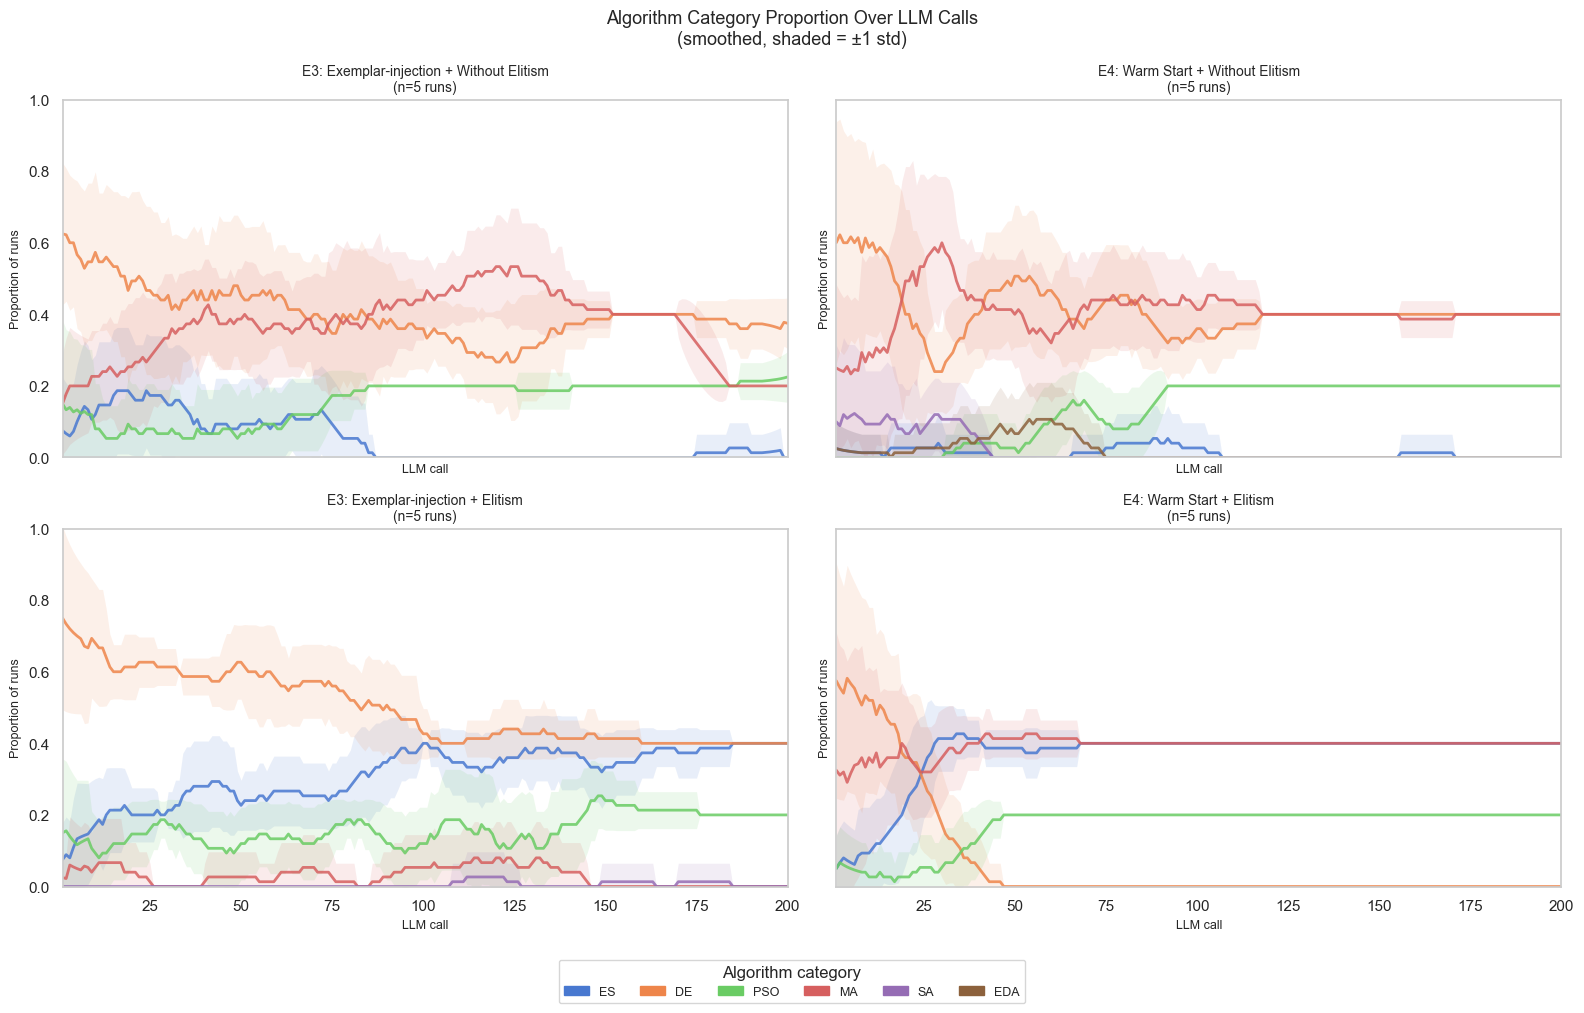

In [30]:

# Check what is causing the white gap in E3
# Minimal check 
# e3_df = log_df[log_df["experiment"] == "E3: Mutation prompts + Without Elitism"]
# print("E3 category distribution:")
# print(e3_df["algorithm_category"].value_counts(dropna=False))
# # confirm this is not the case
# print("\nUnclassified names in E3:")
# print(e3_df[e3_df["algorithm_category"] == "Other"]["name"].value_counts())

# proportion per category over LLM calls

WINDOW = 15  # window again 

fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharex=True, sharey=True)
axes = axes.flatten()

for ax, (exp_label, exp_cfg) in zip(axes, EXPERIMENTS.items()):
    exp_df = log_df[log_df["experiment"] == exp_label]

    if exp_df.empty:
        ax.set_title(f"{exp_label}\n(no data)")
        continue

    exp_df = (
            exp_df
            .sort_values(["run", "call"])
            .drop_duplicates(subset=["run", "call"], keep="last")
        )
    

    n_runs = exp_df["run"].nunique()
    present_cats = [c for c in categories_order if c in exp_df["algorithm_category"].values]

    for cat in present_cats:
        # count how many runs generated this category at each call
        cat_counts = (
            exp_df[exp_df["algorithm_category"] == cat]
            .groupby("call")
            .size()
            .reindex(range(1, BUDGET + 1), fill_value=0)
        )
        proportion = cat_counts / n_runs

        # smooth
        smoothed = proportion.rolling(window=WINDOW, min_periods=1, center=True).mean()

        ax.plot(
            smoothed.index,
            smoothed.values,
            color=category_colors_palette.get(cat, "grey"),
            linewidth=2,
            label=cat,
            alpha=0.85
        )

        # show range 
        ax.fill_between(
            smoothed.index,
            (proportion.rolling(window=WINDOW, min_periods=1, center=True).mean()
             - proportion.rolling(window=WINDOW, min_periods=1, center=True).std().fillna(0)),
            (proportion.rolling(window=WINDOW, min_periods=1, center=True).mean()
             + proportion.rolling(window=WINDOW, min_periods=1, center=True).std().fillna(0)),
            color=category_colors_palette.get(cat, "grey"),
            alpha=0.12,
            linewidth=0
        )
    ax.grid(False)
    ax.set_title(f"{exp_label}\n(n={n_runs} runs)", fontsize=10)
    ax.set_xlim(1, BUDGET)
    ax.set_ylim(0, 1)
    ax.set_xlabel("LLM call", fontsize=9)
    ax.set_ylabel("Proportion of runs", fontsize=9)

handles = [
    mpatches.Patch(color=category_colors_palette[cat], label=cat)
    for cat in categories_order
    if cat in log_df["algorithm_category"].values
]
fig.legend(
    handles=handles,
    title="Algorithm category",
    loc="lower center",
    ncol=len(handles),
    fontsize=9,
    bbox_to_anchor=(0.5, -0.02)
)

plt.grid(False)
plt.suptitle("Algorithm Category Proportion Over LLM Calls\n(smoothed, shaded = ±1 std)", fontsize=13)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()




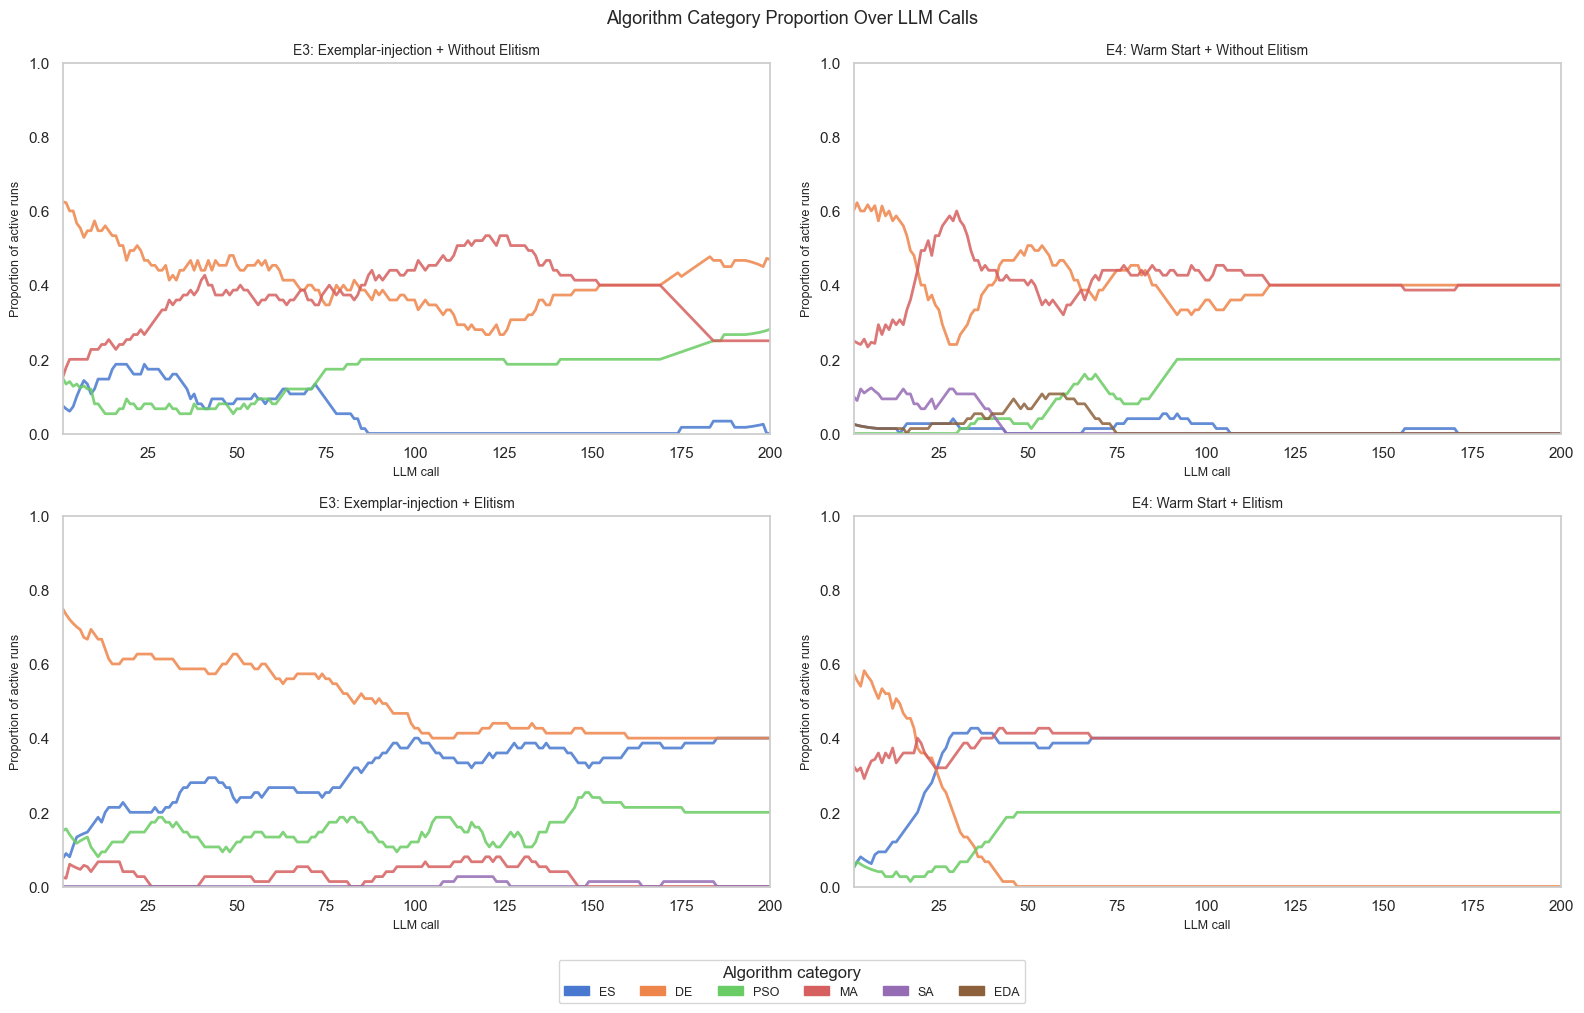

In [31]:
WINDOW = 15
categories_order = ["ES", "DE", "PSO", "MA", "SA", "EDA", "Other"]

categories_with_data = [
    c for c in categories_order
    if c in log_df["algorithm_category"].values
]
palette = ["C0", "C1", "C2", "C3", "C4", "C5", "C6", "C7"]
colors = palette[:len(categories_with_data)]
category_colors_palette = dict(zip(categories_with_data, colors))

fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharex=False, sharey=False)
axes = axes.flatten()

for idx, ((exp_label, exp_cfg), ax) in enumerate(zip(EXPERIMENTS.items(), axes)):
    exp_df = log_df[log_df["experiment"] == exp_label].copy()
    left_plot = (idx % 2 == 0)

    if exp_df.empty:
        ax.set_title(f"{exp_label}\n(no data)")
        ax.tick_params(axis="x", labelsize=8)
        ax.tick_params(axis="y", labelsize=8)
        continue

    # keep only valid rows
    exp_df = exp_df.dropna(subset=["run", "call", "algorithm_category"])

    # if there are multiple rows per run/call, keep one
    exp_df = (
        exp_df
        .sort_values(["run", "call"])
        .drop_duplicates(subset=["run", "call"], keep="last")
    )

    n_runs = exp_df["run"].nunique()

    max_call = int(exp_df["call"].max())
    call_range = range(1, max_call + 1)

    present_cats = [
        c for c in categories_order
        if c in exp_df["algorithm_category"].values
    ]
    active_runs_per_call = (
        exp_df.groupby("call")["run"]
        .nunique()
        .reindex(call_range)
    )

    for cat in present_cats:
        cat_counts = (
            exp_df[exp_df["algorithm_category"] == cat]
            .groupby("call")["run"]
            .nunique()
            .reindex(call_range, fill_value=0)
        )

        # divide by active runs at that call, not always total n_runs
        proportion = cat_counts / active_runs_per_call

        # smooth the lines
        smoothed = proportion.rolling(
            window=WINDOW,
            min_periods=1,
            center=True
        ).mean()
        ax.grid(False)
        ax.plot(
            smoothed.index,
            smoothed.values,
            color=category_colors_palette.get(cat, "grey"),
            linewidth=2,
            label=cat,
            alpha=0.85
        )

    ax.set_title(f"{exp_label}", fontsize=10)
    ax.set_xlim(1, BUDGET)
    ax.set_ylim(0, 1)
    ax.set_xlabel("LLM call", fontsize=9)
    ax.set_ylabel("Proportion of active runs", fontsize=9)

handles = [
    mpatches.Patch(color=category_colors_palette[cat], label=cat)
    for cat in categories_order
    if cat in log_df["algorithm_category"].values
]

fig.legend(
    handles=handles,
    title="Algorithm category",
    loc="lower center",
    ncol=len(handles),
    fontsize=9,
    bbox_to_anchor=(0.5, -0.02)
)

plt.suptitle(
    "Algorithm Category Proportion Over LLM Calls",
    fontsize=13
)
plt.grid(False)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()